In [ ]:
%reset -f

In [ ]:
# block to upload file/dataset
from google.colab import files
uploaded = files.upload()


Saving Event_occurrence_matrix_weblog.csv to Event_occurrence_matrix_weblog (1).csv


K-Means :

In [ ]:
# import block: has all the imports that have been used for K-Means
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import precision_score, recall_score, f1_score
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:


# load the dataset
df = pd.read_csv('Event_occurrence_matrix_weblog.csv')
df.head() #to preview




,BlockId,Label,Type,E1,E2,E3,E4,E5,E6,E7,...,E20,E21,E22,E23,E24,E25,E26,E27,E28,E29
0,blk_-1608999687919862906,Success,NaN,0,0,203,0,10,7,0,...,0,10,1,10,0,4,10,0,0,0
1,blk_7503483334202473044,Success,NaN,0,2,1,0,3,0,0,...,0,3,1,3,0,0,3,0,0,0
2,blk_-3544583377289625738,Fail,21.0,0,0,203,0,3,0,0,...,1,3,1,3,0,0,3,0,0,0
3,blk_-9073992586687739851,Success,NaN,0,3,0,0,3,0,0,...,0,3,1,3,0,0,3,0,0,0
4,blk_7854771516489510256,Success,NaN,0,3,1,15,3,0,0,...,0,3,1,3,0,0,3,0,0,0


In [ ]:
# Map label to binary
df['is_anomaly'] = df['Label'].map({'Success': 0, 'Fail': 1})
#print(df['is_anomaly'])

# Select feature columns
event_cols = [col for col in df.columns if col.startswith('E')]
X = df[event_cols]

y_true = df['is_anomaly']

# #Code to check if anomaly is present or not:

# # Only count types for actual anomaly rows with valid type values
# if 'Type' in df.columns:
#     anomaly_types = df[(df['is_anomaly'] == 1) & (df['Type'].notna())]['Type']
#     if not anomaly_types.empty:
#         print("Anomaly Types:\n", anomaly_types.value_counts())
#     else:
#         print("No non-null anomaly types found.")
# else:
#     print("No 'type' column found.")


In [ ]:
#feature vector clustering


# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


In [ ]:
# PCA to reduce dimensionality

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)


              99      98    97.5 
Recall      0.22    0.64    0.74 
F1-score    0.36    0.77    0.80 
Precision   0.90    0.95    0.87 




/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


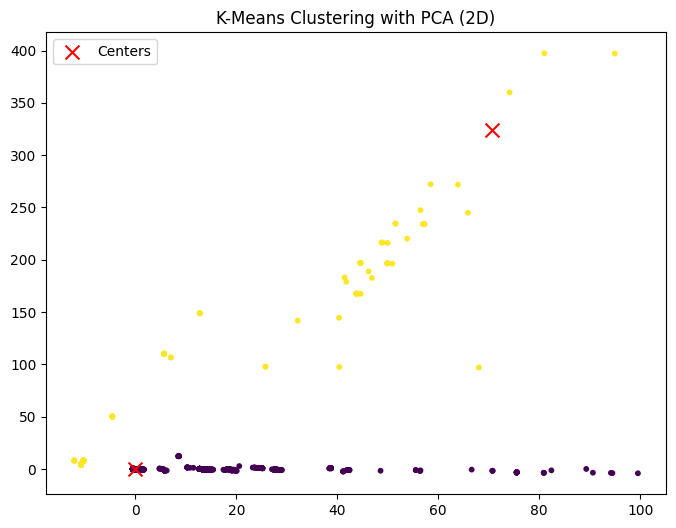

In [ ]:


# X_scaled = normalized features
# y_true = binary labels (0 for normal, 1 for anomaly)

#Applying K-Means algorithm
kmeans = KMeans(n_clusters=2, random_state=None)
cluster_labels = kmeans.fit_predict(X_scaled)

# Calculate distances from each point to its cluster center
distances = np.linalg.norm(X_scaled - kmeans.cluster_centers_[cluster_labels], axis=1)

# Define percentiles to evaluate
percentiles = [99, 98, 97.5] # percentiles for distance-based classification
columns = []
metrics = {'Recall': [], 'F1-score': [], 'Precision': []}

# For each percentile, calculate the scores
for p in percentiles:
    threshold = np.percentile(distances, p)
    y_pred = (distances > threshold).astype(int)

    precision = precision_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    columns.append(f" {p} ")
    metrics['Recall'].append(f" {recall:.2f} ")
    metrics['F1-score'].append(f" {f1:.2f} ")
    metrics['Precision'].append(f" {precision:.2f} ")

# Display results in a table
results = pd.DataFrame(metrics, index=columns).T
print(results.to_string())

print() # line space
print()

# Project the cluster centers into PCA space for easy visualisation
centers_pca = pca.transform(kmeans.cluster_centers_)
kmeans_labels = kmeans.fit_predict(X_pca)

# Visualize

# matplotlib.pyplot is shortened to plt

plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans_labels, cmap='viridis', s=10)
plt.scatter(centers_pca[:, 0], centers_pca[:, 1], c='red', marker='x', s=100, label='Centers')
plt.title('K-Means Clustering with PCA (2D)')
plt.legend()
plt.show()


DBSCAN :

In [ ]:
# import block for DBSCAN implementation:
import pandas as pd
import numpy as np
from sklearn.cluster import DBSCAN
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

from sklearn.neighbors import NearestNeighbors
import matplotlib.pyplot as plt
import numpy as np
from sklearn.preprocessing import StandardScaler

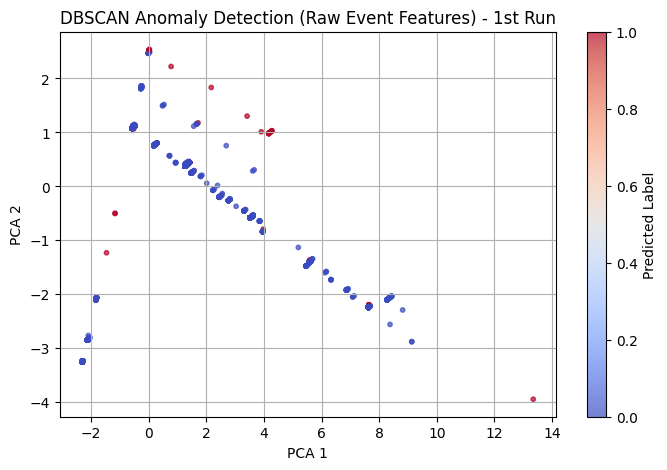

Evaluation Table:
                    Average Recall  Average F1-Score  Average Precision
Algorithm                                                              
DBSCAN (No TF-IDF)            0.23              0.38               0.95


In [ ]:

# Load the dataset
df = pd.read_csv('Event_occurrence_matrix_weblog.csv')

#Initialise metrics
recall = 0
precision = 0
f1 = 0

#Pre-process data

for i in range(0, 5):
  # Sampling dataset (as using entire dataset not feasible due to memory)
  df = df.sample(n=10000, random_state=42)

  # Identify event columns (assume they start with "E")
  event_cols = [col for col in df.columns if col.startswith("E")]

  # Ensure event columns are numeric (if not, convert)
  df[event_cols] = df[event_cols].apply(pd.to_numeric, errors='coerce')
  df.dropna(subset=event_cols, inplace=True)

  # Binary ground truth from label column
  df['true_label'] = df['Label'].apply(lambda x: 1 if x == 'Fail' else 0)

  # Transforming cols

  scaler = StandardScaler()
  X_scaled = scaler.fit_transform(df[event_cols])


  X = df[event_cols].values  # Use event values directly
  dbscan = DBSCAN(eps=2.8, min_samples=18)
  dbscan.fit(X_scaled)

  # Label -1 = anomaly
  df['pred_label'] = (dbscan.labels_ == -1).astype(int)

  # define the metrics

  recall += recall_score(df['true_label'], df['pred_label'], zero_division=0)
  precision += precision_score(df['true_label'], df['pred_label'], zero_division=0)
  f1 += f1_score(df['true_label'], df['pred_label'], zero_division=0)

  if i==1:
    # PCA visualization for first run
    pca = PCA(n_components=2)
    X_pca = pca.fit_transform(X)

    plt.figure(figsize=(8, 5))
    plt.scatter(X_pca[:, 0], X_pca[:, 1], c=df["pred_label"], cmap="coolwarm", s=10, alpha=0.7)
    plt.title("DBSCAN Anomaly Detection (Raw Event Features) - 1st Run")
    plt.xlabel("PCA 1")
    plt.ylabel("PCA 2")
    plt.grid(True)
    plt.colorbar(label="Predicted Label")
    plt.show()

# Take average:
recall /= 5
precision /= 5
f1 /= 5

# Table format
eval_table = pd.DataFrame([{
    "Algorithm": "DBSCAN (No TF-IDF)",
    "Average Recall": round(recall, 2),
    "Average F1-Score": round(f1, 2),
    "Average Precision": round(precision, 2)
}]).set_index("Algorithm")

print("Evaluation Table:")
print(eval_table)


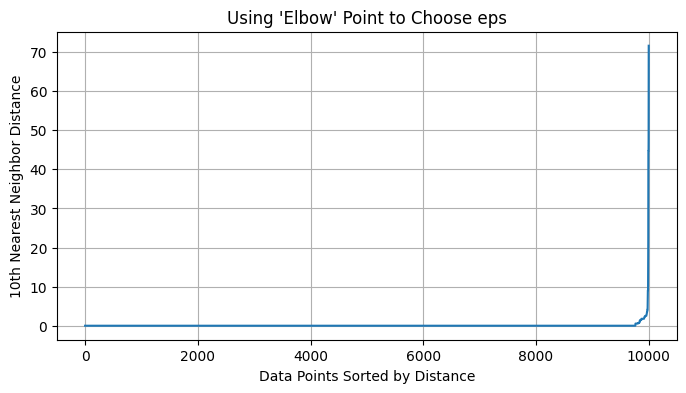

In [ ]:
# calculating eps value from graph

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[event_cols])

neighbors = NearestNeighbors(n_neighbors=10)
neighbors_fit = neighbors.fit(X_scaled)
distances, indices = neighbors_fit.kneighbors(X_scaled)

# Plot k-nearest-neighbours distance graph
k_distances = np.sort(distances[:, 9])  # we are choosing 10th neighbour
plt.figure(figsize=(8, 4))
plt.plot(k_distances)
plt.ylabel("10th Nearest Neighbor Distance")
plt.xlabel("Data Points Sorted by Distance")
plt.title("Using 'Elbow' Point to Choose eps")
plt.grid(True)
plt.show()




TF-IDF Vectorization - HDFS_v1:

In [ ]:
import pandas as pd
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.decomposition import PCA

# reading dataset

df = pd.read_csv("Event_occurrence_matrix_weblog.csv")  # Reads csv file
event_cols = [col for col in df.columns if col.startswith("E")]

# Drop rows with missing event or label values -> not required mostly
# df.dropna(subset=event_cols + ['Label'], inplace=True)

# Convert label to binary: 1 for fail, 0 for success
df['true_label'] = df['Label'].apply(lambda x: 1 if str(x).lower() == 'fail' else 0)

# Creating event sequences for tf-idf

df['event_sequence'] = df[event_cols].astype(str).agg(" ".join, axis=1)

# Performing vectorisation

vectorizer = TfidfVectorizer()
X_tfidf = vectorizer.fit_transform(df['event_sequence'])

# Performing clustering

kmeans = KMeans(n_clusters=3, random_state=42)
kmeans.fit(X_tfidf)

# Compute distances from each point to its cluster center

from sklearn.metrics.pairwise import euclidean_distances
cluster_centers = kmeans.cluster_centers_
assigned_centers = cluster_centers[kmeans.labels_]
distances = np.linalg.norm(X_tfidf - assigned_centers, axis=1)

# Applying threshold

threshold = np.percentile(distances, 97.5) # change this part of code if you want to change threshold
y_pred = (distances > threshold).astype(int)

# Evaluate metrics: Precision, recall and f1-score

y_true = df['true_label'].values

precision = precision_score(y_true, y_pred, zero_division=0)
recall = recall_score(y_true, y_pred, zero_division=0)
f1 = f1_score(y_true, y_pred, zero_division=0)

#print metrics:

print("Evaluation with KMeans + TF-IDF: 97.5th percentile:")
print(f"Precision: {precision:.3f}")
print(f"Recall:    {recall:.3f}")
print(f"F1-Score:  {f1:.3f}")


Evaluation with KMeans + TF-IDF: 97.5th percentile:
Precision: 0.090
Recall:    0.001
F1-Score:  0.002
